# cuBLAST · Basic Linear Algebra Benchmark

**Check correctness before measuring performance.** This notebook covers FP32/FP64
dense matrix multiplication (GEMM), CSR sparse matrix-vector multiplication (SpMV),
CPU/GPU comparisons, and visualizations of data transfer costs.

Choose **Kernel → Restart Kernel and Run All Cells** to run from top to bottom.
Install dependencies using the repository README first. The notebook requires
`benchmark.py` and `plots.py` in the same directory. Uploading only this notebook
to Colab is insufficient; use the entire repository.

- CPU experiments and figures work without an NVIDIA GPU; GPU experiments are explicitly skipped.
- Default inputs are synthetic. For the formal Task B, add three real `.mtx` files in Section 2.
- This baseline does not include TF32/FP16, theoretical GPU peak comparisons, or CG.
- Measurements cover Python library operations, not isolated kernels at their performance limit.


## 1 · Imports and working directory

Start Jupyter from the repository root. All explanations, messages, and chart labels
are in English. The environment check configures GPU settings before importing CuPy
for the first time.


In [1]:
from pathlib import Path
import os
import sys
import json
from datetime import datetime, timezone

ROOT = Path.cwd()
if not (ROOT / "benchmark.py").is_file():
    raise RuntimeError("Switch to the cuBLAST repository directory containing benchmark.py, then run from the beginning.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from benchmark import (
    Config, detect_gpu, environment, correctness_demo, run_gemm, run_spmv,
    make_csr, speedups, export_results,
)
from plots import plot_gemm, plot_spmv, plot_transfers

pd.set_option("display.max_columns", 18)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")


## 2 · Configuration: start with quick, then expand to full

Change `PROFILE` to select experiment sizes. The quick profile runs CPU GEMM up to
1024 and GPU GEMM up to 2048; full extends GPU GEMM to 4096 and CPU GEMM to 2048.
SpMV generates approximately 16 nonzero entries per row. Duplicate random columns
are merged, so the actual nnz is recorded in the results table.

BLAS uses **one thread** by default for reproducibility. This does not represent
peak CPU performance. To compare a multicore CPU configuration, change
`cpu_threads` and document it in your report.

Place SuiteSparse `.mtx` / `.mtx.gz` files in `data/` and add them to `MTX_PATHS`.
File parsing, CSR conversion, and random input generation are excluded from
operation timings. Check memory requirements before loading very large files.


In [2]:
PROFILE = os.environ.get("CUBLAST_PROFILE", "quick")  # quick / full / smoke
PROFILES = {
    "quick": dict(gemm_sizes=(256, 512, 1024, 2048), cpu_max_n=1024,
                  sparse_sizes=(1000, 10000, 100000)),
    "full": dict(gemm_sizes=(256, 512, 1024, 2048, 4096), cpu_max_n=2048,
                 sparse_sizes=(1000, 10000, 100000, 500000)),
    "smoke": dict(gemm_sizes=(64, 128), cpu_max_n=128,
                  sparse_sizes=(100, 1000)),
}
if PROFILE not in PROFILES:
    raise ValueError("PROFILE must be quick, full, or smoke")

cfg = Config(
    **PROFILES[PROFILE],
    dtypes=("float32", "float64"),
    nnz_per_row=16,
    warmup=3,
    repeats=7,
    gpu_gemm_inner=5,
    spmv_inner=20,
    cpu_threads=1,
    seed=42,
    max_host_bytes=1024**3,      # Conservative working-set budget, not a hard process memory limit
    gpu_memory_fraction=0.6,    # Leave headroom for temporary allocations in currently free GPU memory
    enable_gpu=True,
    measure_transfers=True,
)

MTX_PATHS = [
    # ROOT / "data" / "your_matrix_1.mtx",
    # ROOT / "data" / "your_matrix_2.mtx",
    # ROOT / "data" / "your_matrix_3.mtx.gz",
]

display(pd.Series(vars(cfg), name="Configuration").to_frame())


,Configuration
gemm_sizes,"(256, 512, 1024, 2048)"
cpu_max_n,1024
sparse_sizes,"(1000, 10000, 100000)"
nnz_per_row,16
dtypes,"(float32, float64)"
warmup,3
repeats,7
gpu_gemm_inner,5
spmv_inner,20
cpu_threads,1


## 3 · Check the CPU / GPU environment

To distinguish this FP32 baseline from future TF32 experiments, TF32 and optional
acceleration backends are disabled before importing CuPy. SpMV explicitly calls
`cupyx.cusparse.spmv`, using the generic cuSPARSE path.
If CuPy has already been imported, restart the kernel and run from the beginning.

CPU-only results describe CPU performance only. Missing GPU columns or figures
are never filled with simulated values.


In [3]:
gpu = detect_gpu(cfg.enable_gpu)
env = environment(gpu, cfg)
if gpu.available:
    display(Markdown(f"**GPU ready: {gpu.name}**"))
    display(pd.Series(env["gpu"], name="GPU environment").to_frame())
else:
    display(Markdown("**Running CPU-only experiments.** GPU skip reason: " + gpu.reason))

display(pd.Series({
    "Python": sys.version.split()[0],
    "Platform": env["platform"],
    "CPU identifier": env["cpu"],
    "Logical CPUs": env["logical_cpu_count"],
    "BLAS threads requested": cfg.cpu_threads,
    **env["versions"],
}).to_frame("Environment"))
display(pd.DataFrame(env["blas_pools_during_benchmark"]))


**Running CPU-only experiments.** GPU skip reason: CuPy unavailable: No module named 'cupy'

,Environment
Python,3.13.5
Platform,macOS-15.4.1-arm64-arm-64bit-Mach-O
CPU identifier,arm
Logical CPUs,8
BLAS threads requested,1
numpy,2.5.4
scipy,1.18.1
pandas,2.3.3
matplotlib,3.11.2
threadpoolctl,3.7.0


""


## 4 · Understand the operations using small matrices

### 4.1 Dense matrix multiplication: $C=AB$

Start with an example you can calculate by hand to understand the matrix shapes
and output. The benchmark will then increase the problem size.


In [4]:
A = np.array([[1, 2], [3, 4]], dtype=np.float32)
B = np.array([[5, 6], [7, 8]], dtype=np.float32)
C = A @ B
display(pd.DataFrame(C, columns=["column 0", "column 1"]))
np.testing.assert_array_equal(C, [[19, 22], [43, 50]])
print("Small GEMM correctness check passed.")


,column 0,column 1
0,19,22
1,43,50


Small GEMM correctness check passed.


### 4.2 Sparse matrix-vector multiplication: $y=Ax$

CSR stores nonzero values in `data`, column indices in `indices`, and each row's
boundaries in `indptr`. The expected result here is $[7,6,7]^T$, providing a
hand-calculated reference independent of another library.


In [5]:
from scipy import sparse
S = sparse.csr_matrix([[4, 0, 1], [0, 3, 0], [1, 0, 2]], dtype=np.float64)
x = np.array([1, 2, 3], dtype=np.float64)
print("data   =", S.data)
print("indices=", S.indices)
print("indptr =", S.indptr)
print("y      =", S @ x)
np.testing.assert_array_equal(S @ x, [7, 6, 7])


data   = [4. 1. 3. 1. 2.]
indices= [0 2 1 0 2]
indptr = [0 2 3 5]
y      = [7. 6. 7.]


### 4.3 Automated correctness checks

Run both FP32 and FP64 operations on the CPU and on the GPU when available.
GEMM uses a CPU FP64 reference for the small matrices; SpMV uses the
hand-calculated answer above. Relative error uses the vector 2-norm or
matrix Frobenius norm:

$$e=\frac{\|z-z_{\mathrm{ref}}\|}{\|z_{\mathrm{ref}}\|}.$$

Thresholds are $10^{-5}$ for FP32 and $10^{-12}$ for FP64. A failed check stops
execution so correctness can be investigated before benchmarking.


In [6]:
checks = correctness_demo(gpu, cfg)
display(checks)
print("Small-scale correctness checks passed for all available backends.")


,operation,backend,dtype,relative_error,passed
0,GEMM,CPU,float32,1.40269e-07,True
1,SpMV,CPU,float32,0,True
2,GEMM,CPU,float64,0,True
3,SpMV,CPU,float64,0,True


Small-scale correctness checks passed for all available backends.


## 5 · Benchmark GEMM

Each size computes $C=AB$, with approximately $2n^3$ floating-point operations:

$$\mathrm{GFLOP/s}=\frac{2n^3}{t\cdot10^9}.$$

- Warm up first, then repeat measurements and report the median. Time error bars show the interquartile range (IQR).
- CPU timing uses a wall clock. GPU timing uses CUDA Events on the current stream, synchronizing the end event before reading the elapsed time.
- GEMM inputs and outputs are preallocated. Random generation, validation, and transfers are excluded from compute timings.
- Each GPU sample averages several operations to reduce single-call timing variation.
- At each size, up to 16x16 output entries are checked against a CPU FP64 reference.
  This is sampled validation; the small GEMM in Section 4 is validated in full.
- Cases above `cpu_max_n` run only on the GPU. No speedup is calculated without matching CPU data.

CUDA Event intervals can still be affected by Python submission gaps, wrappers,
and contention on a shared GPU.


In [7]:
gemm_results, gemm_samples, gemm_skips = run_gemm(cfg, gpu)
if not gemm_results.empty:
    gemm_view = gemm_results[gemm_results.scope == "compute"].copy()
    gemm_view["median_ms"] = gemm_view.median_s * 1000
    display(gemm_view[["n", "dtype", "backend", "median_ms", "gflops", "relative_error"]])
else:
    display(Markdown("No GEMM measurements. Check the configured sizes and memory budget."))
if not gemm_skips.empty:
    display(gemm_skips)


GEMM float32 n=256


GEMM float32 n=512


GEMM float32 n=1024


GEMM float32 n=2048


GEMM float64 n=256


GEMM float64 n=512


GEMM float64 n=1024


GEMM float64 n=2048


,n,dtype,backend,median_ms,gflops,relative_error
0,256,float32,CPU,0.028667,1170.49,2.69943e-07
1,512,float32,CPU,0.127708,2101.95,4.03221e-07
2,1024,float32,CPU,1.34304,1598.97,4.95822e-07
3,256,float64,CPU,0.101375,330.993,0
4,512,float64,CPU,0.576125,465.933,0
5,1024,float64,CPU,6.56558,327.082,0


,case,dtype,backend,reason
0,gemm_2048,float32,CPU,cpu_max_n
1,gemm_2048,float64,CPU,cpu_max_n


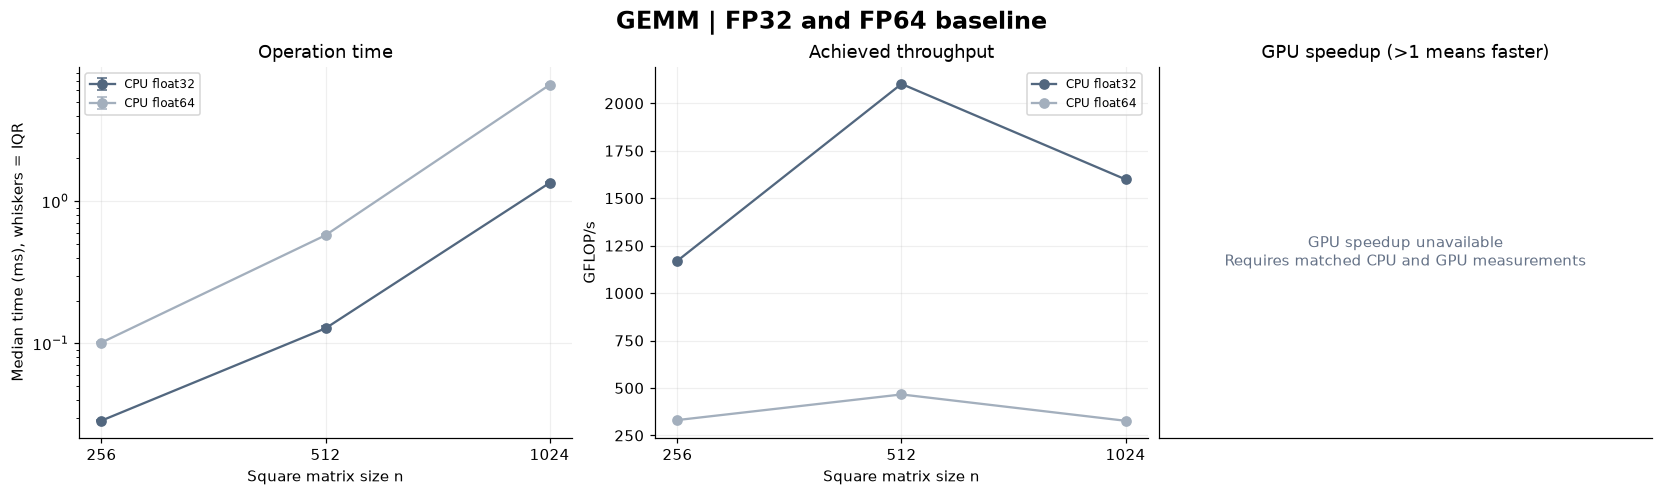

In [8]:
gemm_figure = plot_gemm(gemm_results)
plt.show()


**Reading the figures:** Lower elapsed time means faster execution; higher GFLOP/s
means more arithmetic per second. A speedup above 1 means the GPU is faster.
Dashed curves include transfers; solid curves compare computation with data already
on the device. Observe how throughput changes with size and precision.
Theoretical GPU peaks are not included yet, so these curves alone do not establish
that a hardware compute limit has been reached.


## 6 · Benchmark CSR SpMV

Synthetic matrices are constructed directly in CSR using $O(nk)$ storage, without
creating a dense $n\times n$ array. The same experiments then run on the real
matrices in `MTX_PATHS`; rectangular matrices are supported.

The operation count is approximately $2\,\mathrm{nnz}$. Estimated effective bandwidth uses:

$$B_{\mathrm{est}}=\text{data.nbytes}+\text{indices.nbytes}+\text{indptr.nbytes}
+(n+m)\cdot\text{itemsize},\qquad
\mathrm{GB/s}=\frac{B_{\mathrm{est}}}{t\cdot10^9}.$$

This assumes one read of the CSR arrays and input vector and one write of the
output vector. It is **not hardware-measured DRAM traffic**. Repeated operations
may reuse cached data, so the value is not a direct measure of DRAM bandwidth utilization.

CPU SpMV uses SciPy `matrix @ x`, including allocation of the returned vector.
The GPU output is preallocated, although the cuSPARSE wrapper may still handle
descriptors and workspace. Results therefore compare two actual library call paths.
Every SpMV output is validated in full against an FP64 reference.


In [9]:
if not MTX_PATHS:
    display(Markdown("**Testing synthetic matrices only. Add three real SuiteSparse matrices for the formal Task B.**"))

spmv_results, spmv_samples, spmv_skips = run_spmv(cfg, gpu, MTX_PATHS)
if not spmv_results.empty:
    spmv_view = spmv_results[spmv_results.scope == "compute"].copy()
    spmv_view["median_ms"] = spmv_view.median_s * 1000
    display(spmv_view[["case", "m", "n", "nnz", "dtype", "backend", "median_ms",
                       "effective_gb_s", "relative_error"]])
else:
    display(Markdown("No SpMV measurements. Check the configured sizes and memory budget."))
if not spmv_skips.empty:
    display(spmv_skips)


**Testing synthetic matrices only. Add three real SuiteSparse matrices for the formal Task B.**

SpMV float32 synthetic_1000


SpMV float32 synthetic_10000


SpMV float32 synthetic_100000


SpMV float64 synthetic_1000


SpMV float64 synthetic_10000


SpMV float64 synthetic_100000


,case,m,n,nnz,dtype,backend,median_ms,effective_gb_s,relative_error
0,synthetic_1000,1000,1000,15873,float32,CPU,0.00981875,14.1554,7.63398e-08
1,synthetic_10000,10000,10000,159873,float32,CPU,0.07075,19.7737,7.47343e-08
2,synthetic_100000,100000,100000,1599874,float32,CPU,1.15996,12.0685,7.37666e-08
3,synthetic_1000,1000,1000,15873,float64,CPU,0.0097875,21.505,0
4,synthetic_10000,10000,10000,159873,float64,CPU,0.0746459,28.3804,0
5,synthetic_100000,100000,100000,1599874,float64,CPU,1.34025,15.8168,0


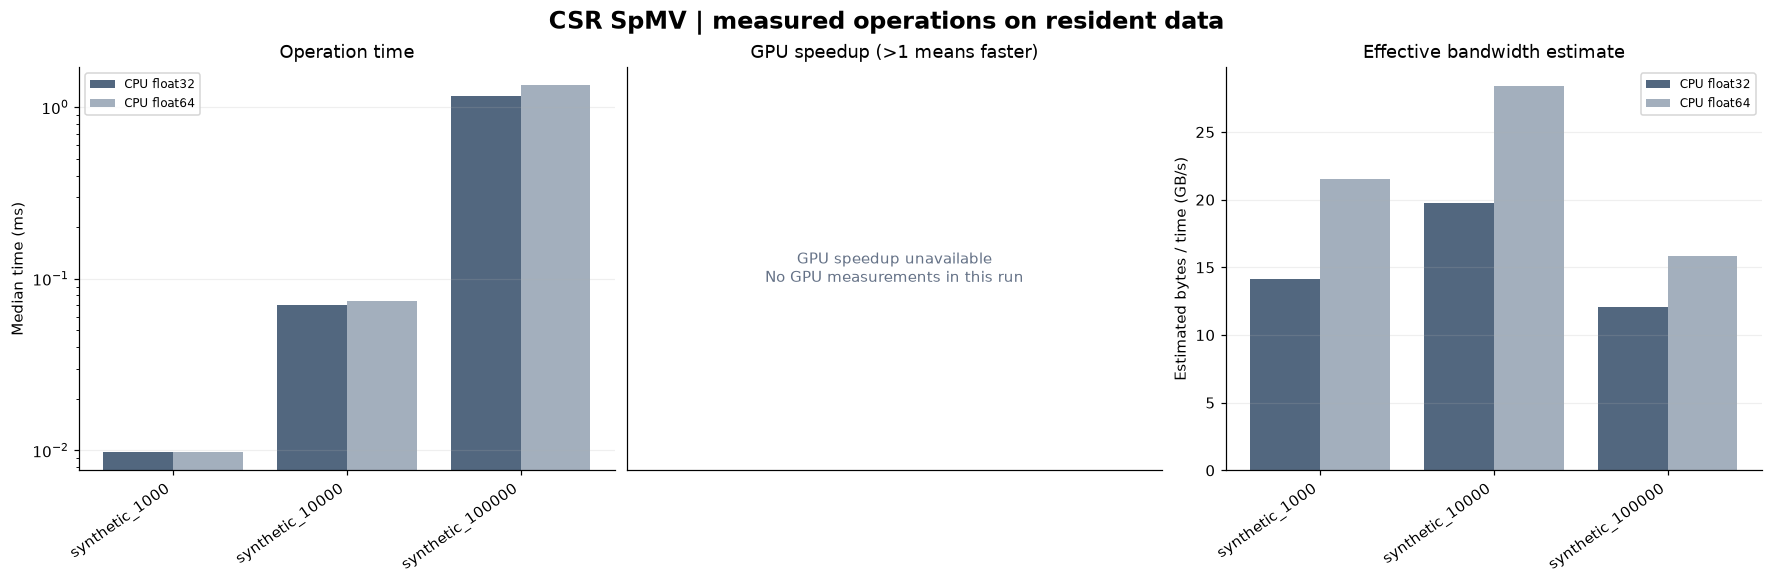

In [10]:
spmv_figure = plot_spmv(spmv_results)
plt.show()


**Reading the figures:** Compare elapsed time, CPU/GPU speedup, and estimated
effective bandwidth across cases. Nonzero distributions in real matrices change
memory access patterns, so row counts alone do not determine performance.
The relatively uniform synthetic cases do not represent all real matrices.


## 7 · Upload / compute / download: why can a GPU be slower?

Each end-to-end trial measures three sequential phases, synchronizing after each:

1. Upload the inputs; SpMV uploads all CSR arrays and the input vector.
2. Execute one operation and synchronize.
3. Download the complete output to the CPU and synchronize.

Input/output buffers are already allocated and the CUDA context is initialized.
Timings exclude file I/O, first-time initialization, and initial allocation.
This experiment uses ordinary NumPy host buffers, without pinned-memory
asynchronous transfer overlap. It measures a defined pipeline with preallocated
buffers, not the entire cost of launching a program for the first time.

The stacked figure uses **phase means from the same trials**, which are additive.
The results table reports the median of the measured total times, rather than
adding phase medians. The single-call compute_wall phase also differs from the
batched CUDA Event compute measurement.


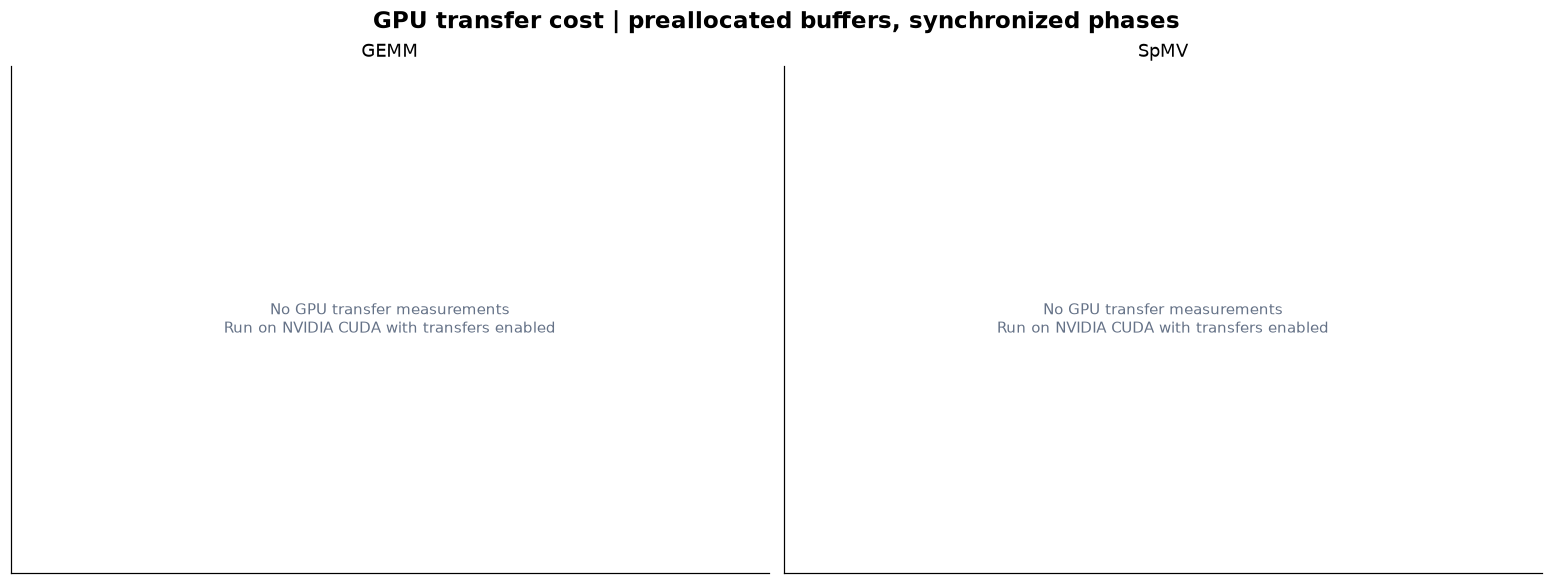

No matching CPU/GPU measurements; speedups are unavailable for this run.

In [11]:
results = pd.concat([gemm_results, spmv_results], ignore_index=True)
samples = pd.concat([gemm_samples, spmv_samples], ignore_index=True)
skips = pd.concat([gemm_skips, spmv_skips], ignore_index=True)
transfer_figure = plot_transfers(samples)
plt.show()

ratios = speedups(results)
if not ratios.empty:
    display(ratios[["operation", "case", "dtype", "scope", "speedup"]])
else:
    display(Markdown("No matching CPU/GPU measurements; speedups are unavailable for this run."))


## 8 · Save the measurements and figures

Each run creates a separate `results/<UTC_timestamp>/` directory containing:

- `results.csv`: medians, quartiles, throughput, estimated bandwidth, and errors.
  GFLOP/s is populated only for compute / end_to_end rows; effective bandwidth
  is populated only for SpMV compute rows. These fields are blank for other phases.
- `samples.csv`: individual measurement samples in seconds; batched timings have already been divided by `inner`.
- `correctness.csv`, `skipped.csv`, and `speedups.csv`.
- `environment.json`: hardware, software versions, BLAS details, parameters, and timing scope.
- Three PNG figures.

Results and matrix datasets are ignored by Git by default. Select the artifacts
you need for your report.


In [12]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = export_results(ROOT / "results" / run_id, cfg, env, results, samples, skips, checks)
for name, figure in (("gemm", gemm_figure), ("spmv", spmv_figure),
                     ("transfers", transfer_figure)):
    figure.savefig(output_dir / f"{name}.png", dpi=160, bbox_inches="tight")
print("Results saved to:", output_dir)
display(pd.DataFrame({"file": [p.name for p in sorted(output_dir.iterdir())]}))


Results saved to: /Users/liaowei/Desktop/cuBLAST/results/20261015T135304_925116Z


,file
0,correctness.csv
1,environment.json
2,gemm.png
3,results.csv
4,samples.csv
5,skipped.csv
6,speedups.csv
7,spmv.png
8,transfers.png


## 9 · Record your observations

Answer using your measured results:

1. At which tested sizes does GEMM throughput begin to level off? How do FP32 and FP64 differ?
2. For which cases is GPU compute faster? Does including transfers change the conclusion?
3. How does estimated SpMV bandwidth vary with size? How might caching and sparsity patterns affect it?
4. How many CPU BLAS threads were used? Was the GPU shared? Which overheads are included?
5. If this was a CPU-only run, state explicitly that GPU performance has not been measured.

Four team members can extend the baseline with FP64/FP32 size studies,
TF32/FP16 and theoretical peak comparisons, three SuiteSparse matrices, and GPU CG.
Stabilize the foundational experiments before adding CG.

References: [CuPy performance and timing](https://docs.cupy.dev/en/stable/user_guide/performance.html),
[CuPy environment variables](https://docs.cupy.dev/en/stable/reference/environment.html),
[CuPy installation](https://docs.cupy.dev/en/stable/install.html),
[CuPy sparse matrices](https://docs.cupy.dev/en/stable/reference/scipy_sparse.html),
and the [SuiteSparse Matrix Collection](https://sparse.tamu.edu/).
